In [1]:
## Step 1: Load from saved master file and prepare full sample for plsdo

import pandas as pd
import numpy as np
import os

save_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\input_arrays\pls_regression'

master = pd.read_csv(os.path.join(save_path, 'master_RS.csv'), dtype={'UniqueID': str})
print(f"Master loaded: {master.shape}")

# Define EEG features — same 21 features will be used in clustering analysis

eeg_features = [
    'frontocentral_W50_100', 'frontocentral_W100_150', 'frontocentral_W150_200',
    'frontocentral_W200_250', 'frontocentral_W250_300',
    'P1_amp_diff', 'N1_amp_diff', 'P2_amp_diff',
    'P1_lat_diff', 'N1_lat_diff', 'P2_lat_diff',
    'power_slow_poststim_diff', 'power_fast_theta_poststim_diff',
    'power_alpha_poststim_diff', 'power_low_beta_poststim_diff',
    'power_high_beta_poststim_diff',
    'itpc_slow_poststim_diff', 'itpc_fast_theta_poststim_diff',
    'itpc_alpha_poststim_diff', 'itpc_low_beta_poststim_diff',
    'itpc_high_beta_poststim_diff',
]

# Y variables — IQ only (common to both groups)
y_full_cols = ['viq', 'piq', 'fsiq']

# Full sample only
full_sample = master.copy()
print(f"Full sample: {full_sample.shape[0]} subjects")

# Check NaNs in clinical variables
print("\n=== NaNs in clinical variables ===")
print(full_sample[y_full_cols].isna().sum())

# Check NaNs in EEG features
print("\n=== NaNs in EEG features ===")
print(f"Full sample: {full_sample[eeg_features].isna().sum().sum()}")

# Drop subjects with missing IQ variables
print("\n=== Drop subjects with missing Y variables ===")
n_before = full_sample.shape[0]
full_sample = full_sample.dropna(subset=y_full_cols).reset_index(drop=True)
print(f"Before: {n_before} | After: {full_sample.shape[0]} | Dropped: {n_before - full_sample.shape[0]}")

Master loaded: (372, 88)
Full sample: 372 subjects

=== NaNs in clinical variables ===
viq     8
piq     5
fsiq    6
dtype: int64

=== NaNs in EEG features ===
Full sample: 0

=== Drop subjects with missing Y variables ===
Before: 372 | After: 364 | Dropped: 8


In [2]:
## Interim Step: Demographic breakdown before and after dropping
print(f"=== BEFORE dropping ({len(master)} subjects) ===")
print(master['group_original'].value_counts())

print(f"\n=== AFTER dropping ({len(full_sample)} subjects) ===")
print(full_sample['group_original'].value_counts())

dropped = master[~master['UniqueID'].isin(full_sample['UniqueID'])]
print(f"\n=== DROPPED ({len(dropped)} subjects) ===")
print(dropped['group_original'].value_counts())

=== BEFORE dropping (372 subjects) ===
group_original
ASD    201
TD     171
Name: count, dtype: int64

=== AFTER dropping (364 subjects) ===
group_original
ASD    194
TD     170
Name: count, dtype: int64

=== DROPPED (8 subjects) ===
group_original
ASD    7
TD     1
Name: count, dtype: int64


In [3]:
# Step 2: Build EEG feature reference table (raw name, publication label, definition) and save
import pandas as pd
import os

save_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures'

# raw name -> (EEG Feature, Description)
feature_info = {
    'frontocentral_W50_100':          ('FC 50-100 ms  (Δ)',   'Fronto-central mean amplitude, 50-100 ms window'),
    'frontocentral_W100_150':         ('FC 100-150 ms (Δ)',   'Fronto-central mean amplitude, 100-150 ms window'),
    'frontocentral_W150_200':         ('FC 150-200 ms (Δ)',   'Fronto-central mean amplitude, 150-200 ms window'),
    'frontocentral_W200_250':         ('FC 200-250 ms (Δ)',   'Fronto-central mean amplitude, 200-250 ms window'),
    'frontocentral_W250_300':         ('FC 250-300 ms (Δ)',   'Fronto-central mean amplitude, 250-300 ms window'),
    'P1_amp_diff':                    ('P1 amplitude  (Δ)',   'Std2-Std1 difference in P1 amplitude'),
    'N1_amp_diff':                    ('N1 amplitude  (Δ)',   'Std2-Std1 difference in N1 amplitude'),
    'P2_amp_diff':                    ('P2 amplitude  (Δ)',   'Std2-Std1 difference in P2 amplitude'),
    'P1_lat_diff':                    ('P1 latency (Δ)',      'Std2-Std1 difference in P1 latency'),
    'N1_lat_diff':                    ('N1 latency (Δ)',      'Std2-Std1 difference in N1 latency'),
    'P2_lat_diff':                    ('P2 latency (Δ)',      'Std2-Std1 difference in P2 latency'),
    'power_slow_poststim_diff':       ('δ–slow θ power (Δ)',  'Std2-Std1 post-stimulus delta-slow theta (2-6 hz) power'),
    'power_fast_theta_poststim_diff': ('Fast θ power (Δ)',    'Std2-Std1 post-stimulus fast theta (6-9 hz) power'),
    'power_alpha_poststim_diff':      ('α power (Δ)',         'Std2-Std1 post-stimulus alpha (9-13 hz) power'),
    'power_low_beta_poststim_diff':   ('Low-β power (Δ)',     'Std2-Std1 post-stimulus low-beta (13-20 hz) power'),
    'power_high_beta_poststim_diff':  ('High-β power (Δ)',    'Std2-Std1 post-stimulus high-beta (20-30 hz) power'),
    'itpc_slow_poststim_diff':        ('δ–slow θ ITPC (Δ)',   'Std2-Std1 post-stimulus delta-slow theta ITPC'),
    'itpc_fast_theta_poststim_diff':  ('Fast θ ITPC (Δ)',     'Std2-Std1 post-stimulus fast theta ITPC'),
    'itpc_alpha_poststim_diff':       ('α ITPC (Δ)',          'Std2-Std1 post-stimulus alpha ITPC'),
    'itpc_low_beta_poststim_diff':    ('Low-β ITPC (Δ)',      'Std2-Std1 post-stimulus low-beta ITPC'),
    'itpc_high_beta_poststim_diff':   ('High-β ITPC (Δ)',     'Std2-Std1 post-stimulus high-beta ITPC'),
}

# build dataframe (dict preserves insertion order)
feature_table = pd.DataFrame(
    [(raw, lab, defn) for raw, (lab, defn) in feature_info.items()],
    columns=['raw_name', 'EEG Feature', 'Description']
)

# save table
feature_table.to_csv(os.path.join(save_path, 'Table1_eeg_feature_labels.csv'), index=False, encoding='utf-8-sig')
print(f"Saved table: {feature_table.shape[0]} features")

# rename dict for plotting (raw -> publication label)
label_map = dict(zip(feature_table['raw_name'], feature_table['EEG Feature']))

# ordered publication-label list (matches eeg_features order)
pub_labels = feature_table['EEG Feature'].tolist()

# save both for later use
import json
with open(os.path.join(save_path, 'label_map.json'), 'w', encoding='utf-8') as f:
    json.dump(label_map, f, ensure_ascii=False, indent=2)

feature_table

Saved table: 21 features


,raw_name,EEG Feature,Description
0,frontocentral_W50_100,FC 50-100 ms (Δ),"Fronto-central mean amplitude, 50-100 ms window"
1,frontocentral_W100_150,FC 100-150 ms (Δ),"Fronto-central mean amplitude, 100-150 ms window"
2,frontocentral_W150_200,FC 150-200 ms (Δ),"Fronto-central mean amplitude, 150-200 ms window"
3,frontocentral_W200_250,FC 200-250 ms (Δ),"Fronto-central mean amplitude, 200-250 ms window"
4,frontocentral_W250_300,FC 250-300 ms (Δ),"Fronto-central mean amplitude, 250-300 ms window"
5,P1_amp_diff,P1 amplitude (Δ),Std2-Std1 difference in P1 amplitude
6,N1_amp_diff,N1 amplitude (Δ),Std2-Std1 difference in N1 amplitude
7,P2_amp_diff,P2 amplitude (Δ),Std2-Std1 difference in P2 amplitude
8,P1_lat_diff,P1 latency (Δ),Std2-Std1 difference in P1 latency
9,N1_lat_diff,N1 latency (Δ),Std2-Std1 difference in N1 latency


In [4]:
# Step 3: IQR-based iterative outlier removal on EEG features
def remove_outliers_col(df, col):
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    return df[(df[col] >= Q1 - 2.5*IQR) & (df[col] <= Q3 + 2.5*IQR)]

df_clean = full_sample.copy()
n_before = len(df_clean)

for col in eeg_features:
    df_clean = remove_outliers_col(df_clean, col)

n_after = len(df_clean)
print(f"Subjects before outlier removal: {n_before}")
print(f"Subjects after outlier removal: {n_after}")
print(f"Subjects removed: {n_before - n_after}")
print(df_clean['group_original'].value_counts())

Subjects before outlier removal: 364
Subjects after outlier removal: 307
Subjects removed: 57
group_original
ASD    166
TD     141
Name: count, dtype: int64


In [5]:
# Step 4 — Regress age out of X and Y matrices
from sklearn.linear_model import LinearRegression

def regress_out_age(df, feature_cols):
    """Regress age out of all feature columns, return residuals"""
    age = df[['age_years']].values  # extracts the age column as a numpy array (the predictor)
    residuals = df[feature_cols].copy()  # makes a copy of all feature columns to store results in
    
    for col in feature_cols:  # for each column
        reg = LinearRegression().fit(age, df[col].values)  # fits a straight line between age and that feature
        residuals[col] = df[col].values - reg.predict(age)  # subtracts age-predicted values, leaving age-independent variance
    
    return residuals  # returns the dataframe with all features replaced by their age-residuals

# Full sample only
X_clean = regress_out_age(df_clean, eeg_features)
Y_clean = regress_out_age(df_clean, y_full_cols)

print("Age regression complete")
print(f"X_clean: {X_clean.shape}, Y_clean: {Y_clean.shape}")
print(df_clean['group_original'].value_counts())

Age regression complete
X_clean: (307, 21), Y_clean: (307, 3)
group_original
ASD    166
TD     141
Name: count, dtype: int64


In [6]:
# Step 5 — Export CSVs for plsdo
# plsdo requires: brain_measures.csv, behaviour_scores.csv, participants.csv
# UniqueID is used as subject identifier (SubjectID is not unique across cohorts)

import os

analysis_name = "analysis_october"   # change this for each analysis

pls_path = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_inputs\{analysis_name}'

os.makedirs(pls_path, exist_ok=True)

# Add UniqueID back to X and Y
X_clean.insert(0, 'UniqueID', df_clean['UniqueID'].values)
Y_clean.insert(0, 'UniqueID', df_clean['UniqueID'].values)
participants_clean = df_clean[['UniqueID', 'group_original', 'age_group', 'sex', 'age_years']].copy()

X_clean.to_csv(os.path.join(pls_path, f'brain_measures_{analysis_name}.csv'), index=False)
Y_clean.to_csv(os.path.join(pls_path, f'behaviour_scores_{analysis_name}.csv'), index=False)
participants_clean.to_csv(os.path.join(pls_path, f'participants_{analysis_name}.csv'), index=False)

print("Files saved to:", pls_path)
print("Files saved:", [f for f in os.listdir(pls_path)])


Files saved to: C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_inputs\analysis_october
Files saved: ['.ipynb_checkpoints', 'behaviour_scores_analysis_october.csv', 'brain_measures_analysis_october.csv', 'participants_analysis_october.csv']


In [7]:
# Step 6: PLS terminal command builder and run command in terminal

# NOTE: build cmd as ONE line (no backslash line-continuations). The \ continuation
# is Bash (Mac/Linux) syntax and fails in Windows Anaconda Prompt, which needs the
# full command on a single line. String fragments below concatenate with trailing
# spaces into one continuous line, ready to paste and run.


analysis_name = "analysis_october"          # change this for each analysis

base = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression'
inputs  = f"{base}/plsdo_inputs/{analysis_name}"
outputs = f"{base}/plsdo_outputs/{analysis_name}"

cmd = (
    f'plsdo run --method c '
    f'--x "{inputs}/brain_measures_{analysis_name}.csv" '
    f'--y "{inputs}/behaviour_scores_{analysis_name}.csv" '
    f'--demographics "{inputs}/participants_{analysis_name}.csv" '
    f'--group-col group_original '
    f'--subject-id UniqueID '
    f'--output "{outputs}"'
)
print(cmd)

# Steps for running PLS analysis

# Open Anaconda terminal (Anaconda Prompt).
# Activate the environment: conda activate plsdo_env
# Paste the printed command (below) and run.

# It writes results to the plsdo_outputs/analysis folder.

plsdo run --method c --x "C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression/plsdo_inputs/analysis_october/brain_measures_analysis_october.csv" --y "C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression/plsdo_inputs/analysis_october/behaviour_scores_analysis_october.csv" --demographics "C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression/plsdo_inputs/analysis_october/participants_analysis_october.csv" --group-col group_original --subject-id UniqueID --output "C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression/plsdo_outputs/analysis_october"


In [9]:
## Step 7: check the subject_scores.csv to verify each subject has exactly one row:

analysis_name = "analysis_october"          # change this for each analysis

scores_path = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_outputs\{analysis_name}\data\subject_scores.csv'
scores = pd.read_csv(scores_path, dtype={'UniqueID': str})
print(f"Shape: {scores.shape}")
print(f"Unique subjects: {scores['UniqueID'].nunique()}")
print(scores.head())

Shape: (307, 3)
Unique subjects: 307
       UniqueID     X_LV1     Y_LV1
0  104324981539  0.717386 -1.242410
1  109182897329  0.049434  0.795026
2  112353982965 -2.787819  0.000501
3  113902830642  1.677050 -1.325954
4  114414660031  0.404923 -1.150780


-0.171 0.142


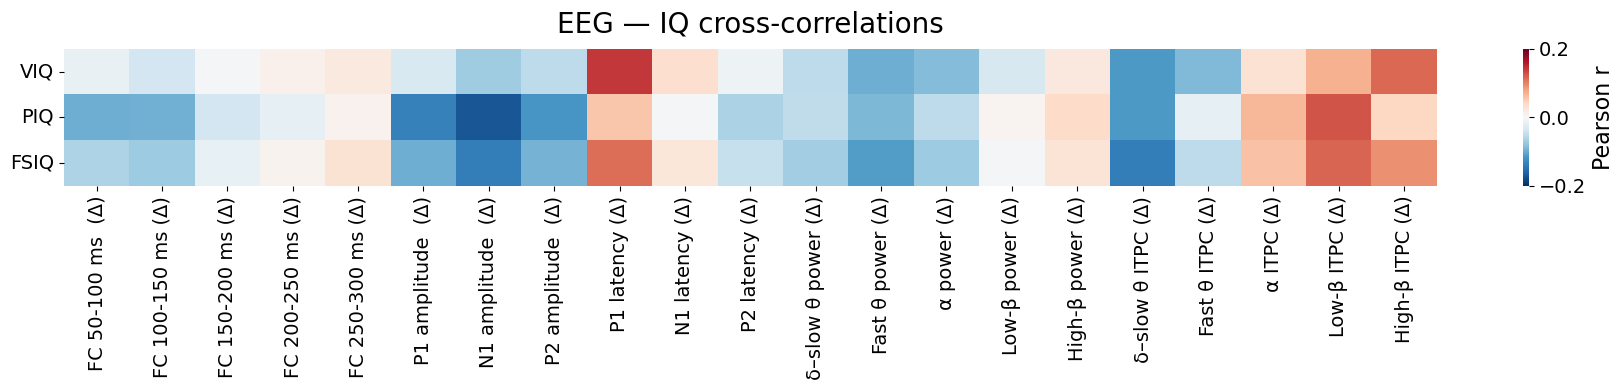

In [3]:
## Step 8: After running plsdo - Recreate cross-correlation heatmap with proper colour scale  - figure 4.1

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import os
import pandas as pd


analysis_name = "analysis_october"          # change this for each analysis

import json
# reload the label map saved in Step 2
with open(r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\label_map.json', encoding='utf-8') as f:
    label_map = json.load(f)

pls_input_path  = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_inputs\{analysis_name}'
pls_output_path = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_outputs\{analysis_name}'

X_reload = pd.read_csv(os.path.join(pls_input_path, f'brain_measures_{analysis_name}.csv'))
Y_reload = pd.read_csv(os.path.join(pls_input_path, f'behaviour_scores_{analysis_name}.csv'))

eeg_cols_pls = [c for c in X_reload.columns if c != 'UniqueID']
y_cols_pls   = [c for c in Y_reload.columns if c != 'UniqueID']

corr_matrix = pd.DataFrame(index=eeg_cols_pls, columns=y_cols_pls)

for eeg in eeg_cols_pls:
    for y in y_cols_pls:
        r, _ = pearsonr(X_reload[eeg], Y_reload[y])
        corr_matrix.loc[eeg, y] = r
corr_matrix = corr_matrix.astype(float)
print(round(corr_matrix.min().min(), 3), round(corr_matrix.max().max(), 3))

fig, ax = plt.subplots(figsize=(18, 4))
sns.heatmap(corr_matrix.T,
            cmap='RdBu_r',
            vmin=-0.2, vmax=0.2,
            center=0,
            ax=ax,
            cbar_kws={'label': 'Pearson r'})
new_xlabels = [label_map.get(c, c) for c in eeg_cols_pls]
ax.set_xticklabels(new_xlabels, rotation=90)
# x and y tick label font size
ax.tick_params(axis='both', labelsize=14)
ax.set_yticklabels([y.upper() for y in y_cols_pls], rotation=0)
ax.set_title('EEG — IQ cross-correlations', fontsize=20, pad=12)
ax.set_xlabel('')
ax.set_ylabel('')

# colorbar (legend) label + tick font size
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14)
cbar.set_label('Pearson r', size=16)

plt.tight_layout()

# save heatmap as figure4_1 in png + pdf + tif
fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\figure_4'
os.makedirs(fig_path, exist_ok=True)

plt.savefig(os.path.join(fig_path, 'figure4_1.png'), format='png', dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure4_1.tif'), format='tif', dpi=300, bbox_inches='tight')           
plt.savefig(os.path.join(fig_path, 'figure4_1.pdf'), format='pdf', bbox_inches='tight')
            
plt.show()

## a diverging colourmap like RdBu_r with a symmetric scale (e.g. vmin=-0.2, vmax=0.2) is used so that:
# Red = positive correlation
# Blue = negative correlation
# White = zero

In [2]:
print(X_reload.shape, Y_reload.shape, X_reload.isna().sum().sum(), Y_reload.isna().sum().sum())

(307, 22) (307, 4) 0 0


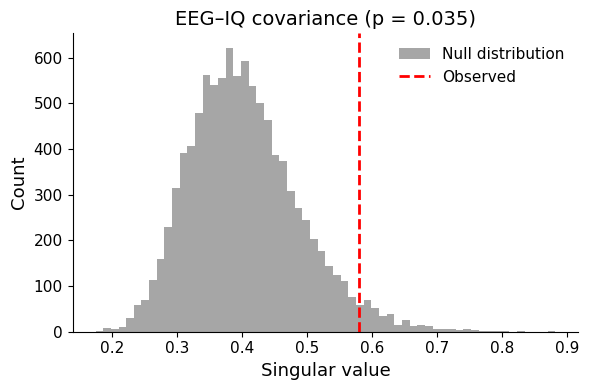

Observed LV1 SV: 0.5792 | p = 0.0355


In [11]:
## Step 9: Recreate permutation distribution for LV1 only (because only LV1 significant) - figure 4.2

import numpy as np, pandas as pd, os
import matplotlib.pyplot as plt

np.random.seed(42)  # reproducibility

analysis_name = "analysis_october"
pls_input_path  = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_inputs\{analysis_name}'
pls_output_path = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_outputs\{analysis_name}'

# load X and Y (already age-regressed, outlier-cleaned), drop ID
X = pd.read_csv(os.path.join(pls_input_path, f'brain_measures_{analysis_name}.csv')).drop(columns='UniqueID').values
Y = pd.read_csv(os.path.join(pls_input_path, f'behaviour_scores_{analysis_name}.csv')).drop(columns='UniqueID').values

# z-score both matrices (plsdo standardises before SVD)
X = (X - X.mean(0)) / X.std(0, ddof=1)
Y = (Y - Y.mean(0)) / Y.std(0, ddof=1)
n = X.shape[0]

# observed LV1 singular value
def lv1_sv(Xm, Ym):
    R = (Xm.T @ Ym) / (n - 1)          # cross-covariance
    return np.linalg.svd(R, compute_uv=False)[0]

observed = lv1_sv(X, Y)

# permutation: shuffle Y rows, recompute LV1 singular value
nperm = 10000
null = np.empty(nperm)
for i in range(nperm):
    perm = np.random.permutation(n)
    null[i] = lv1_sv(X, Y[perm, :])

p_lv1 = (np.sum(null >= observed) + 1) / (nperm + 1)

# plot
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(null, bins=60, color='grey', alpha=0.7, label='Null distribution')
ax.axvline(observed, color='red', linestyle='--', linewidth=2, label='Observed')

ax.set_xlabel('Singular value', fontsize=13)
ax.set_ylabel('Count', fontsize=13)
ax.set_title(f'EEG–IQ covariance (p = {p_lv1:.3f})', fontsize=14)
ax.tick_params(labelsize=11)
ax.legend(fontsize=11, frameon=False)

# remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# save histogram as figure4_2 in png + pdf + tif
fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\figure_4'
os.makedirs(fig_path, exist_ok=True)

plt.savefig(os.path.join(fig_path, 'figure4_2.png'), format='png', dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure4_2.tif'), format='tif', dpi=300, bbox_inches='tight')           
plt.savefig(os.path.join(fig_path, 'figure4_2.pdf'), format='pdf', bbox_inches='tight')
            
plt.show()

print(f"Observed LV1 SV: {observed:.4f} | p = {p_lv1:.4f}")


In [12]:
# Step 10 Part 1: Bootstrap CI for LV1 loadings (X and Y)
import numpy as np, pandas as pd, os
import matplotlib.pyplot as plt

np.random.seed(42)
analysis_name = "analysis_october"
pls_input_path = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_inputs\{analysis_name}'
pls_output_path = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_outputs\{analysis_name}'

# load, drop ID, z-score
Xdf = pd.read_csv(os.path.join(pls_input_path, f'brain_measures_{analysis_name}.csv')).drop(columns='UniqueID')
Ydf = pd.read_csv(os.path.join(pls_input_path, f'behaviour_scores_{analysis_name}.csv')).drop(columns='UniqueID')
eeg_names, iq_names = Xdf.columns.tolist(), Ydf.columns.tolist()
X = ((Xdf - Xdf.mean()) / Xdf.std(ddof=1)).values
Y = ((Ydf - Ydf.mean()) / Ydf.std(ddof=1)).values
n = X.shape[0]

# LV1 loadings from full sample (sign-anchored)
def lv1_loadings(Xm, Ym):
    U, s, Vt = np.linalg.svd((Xm.T @ Ym) / (n - 1), full_matrices=False)
    return U[:, 0], Vt[0, :]
x_load, y_load = lv1_loadings(X, Y)

# bootstrap: resample subjects, recompute loadings, align sign to observed
nboot = 10000
x_boot = np.empty((nboot, len(eeg_names)))
y_boot = np.empty((nboot, len(iq_names)))
for i in range(nboot):
    idx = np.random.randint(0, n, n)
    xb, yb = lv1_loadings(X[idx], Y[idx])
    if np.dot(xb, x_load) < 0:      # flip sign if bootstrap vector points opposite
        xb, yb = -xb, -yb
    x_boot[i], y_boot[i] = xb, yb

# 95% CI (percentiles)
x_ci = np.percentile(x_boot, [2.5, 97.5], axis=0)
y_ci = np.percentile(y_boot, [2.5, 97.5], axis=0)
print("Bootstrap done:", x_boot.shape, y_boot.shape)


Bootstrap done: (10000, 21) (10000, 3)


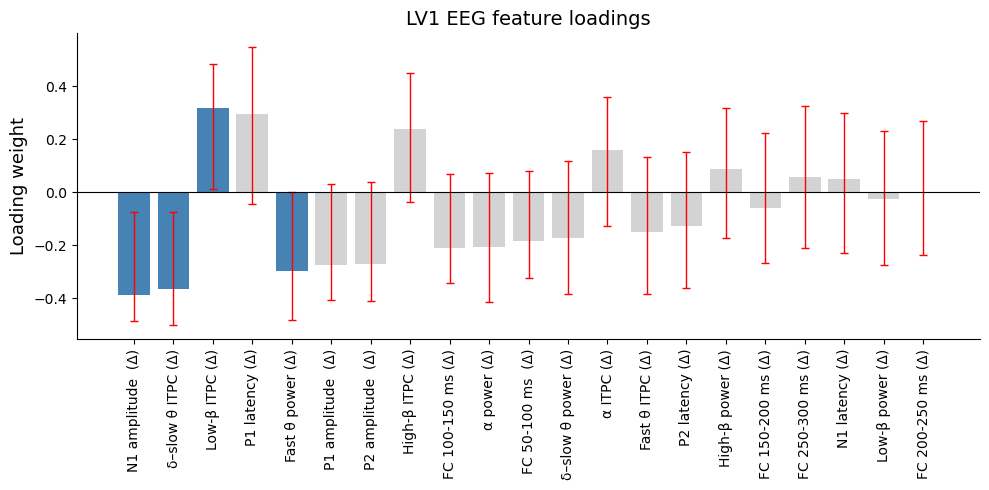

In [13]:
# Step 10 Part 2: EEG LV1 loadings plot - figure 4.3a
import json

# reload publication labels (for the loadings)
with open(r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\label_map.json', encoding='utf-8') as f:
    label_map = json.load(f)

# order features by loading magnitude (largest first)
order = np.argsort(np.abs(x_load))[::-1]
labels = [label_map.get(eeg_names[i], eeg_names[i]) for i in order]
vals = x_load[order]
lo = vals - x_ci[0, order]        # lower error length
hi = x_ci[1, order] - vals        # upper error length

# reliable if CI excludes zero
#reliable = (x_ci[0, order] > 0) | (x_ci[1, order] < 0)
#colors = ['steelblue' if r else 'lightgrey' for r in reliable]

# reliability from saved bootstrap ratios (|BR| > 1.96),
bsr = pd.read_csv(os.path.join(pls_output_path, 'data', 'x_bootstrap_ratios.csv'), index_col=0)['LV1']
bsr = bsr.reindex(eeg_names).values          # align to eeg_names order
reliable = np.abs(bsr[order]) > 1.96
colors = ['steelblue' if r else 'lightgrey' for r in reliable]


fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(len(vals)), vals, yerr=[lo, hi], color=colors,
       capsize=3, error_kw={'ecolor': 'red', 'elinewidth': 1})
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(labels, rotation=90, fontsize=10)
ax.set_ylabel('Loading weight', fontsize=13)
ax.set_title('LV1 EEG feature loadings', fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()

fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\figure_4'
plt.savefig(os.path.join(fig_path, 'figure4_3a.png'), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure4_3a.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure4_3a.tif'), dpi=300, bbox_inches='tight')
plt.show()

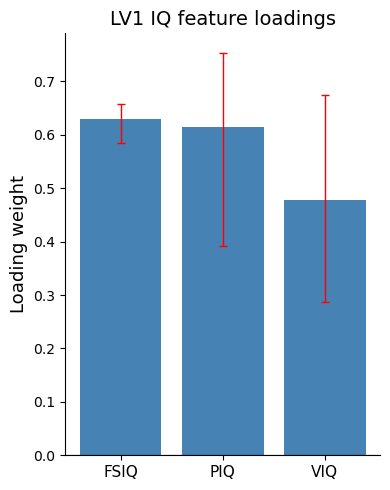

In [14]:
# Step 10 Part 3: IQ LV1 loadings plot - figure 4.3b
import json

analysis_name = "analysis_october"
pls_output_path = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_outputs\{analysis_name}'

# order IQ features by loading magnitude
order = np.argsort(np.abs(y_load))[::-1]
labels = [iq_names[i].upper() for i in order]        # viq/piq/fsiq -> VIQ/PIQ/FSIQ
vals = y_load[order]
lo = vals - y_ci[0, order]
hi = y_ci[1, order] - vals

# reliability from saved bootstrap ratios (|BR| > 1.96)
bsr = pd.read_csv(os.path.join(pls_output_path, 'data', 'y_bootstrap_ratios.csv'), index_col=0)['LV1']
bsr = bsr.reindex(iq_names).values
reliable = np.abs(bsr[order]) > 1.96
colors = ['steelblue' if r else 'lightgrey' for r in reliable]

fig, ax = plt.subplots(figsize=(4, 5))
ax.bar(range(len(vals)), vals, yerr=[lo, hi], color=colors,
       capsize=3, error_kw={'ecolor': 'red', 'elinewidth': 1})
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(labels, rotation=0, fontsize=11)
ax.set_ylabel('Loading weight', fontsize=13)
ax.set_title('LV1 IQ feature loadings', fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()

fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\figure_4'
plt.savefig(os.path.join(fig_path, 'figure4_3b.png'), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure4_3b.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure4_3b.tif'), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# the difference between setting 1.96 thershold vs having zero in the 95% CI?
# They're testing the same idea but not identical in practice.
    # BR > 1.96 treats the bootstrap ratio (loading/SE) like a z-score and assumes the bootstrap distribution is roughly normal. 1.96 is the 
    # normal cutoff for 95%. So it asks: is the loading more than ~2 standard errors from zero, assuming normality?
# Zero outside the 95% CI uses the actual percentiles (2.5th, 97.5th) of the bootstrap distribution. It makes no normality assumption — it 
   # looks at where the middle 95% of resampled loadings actually fall.

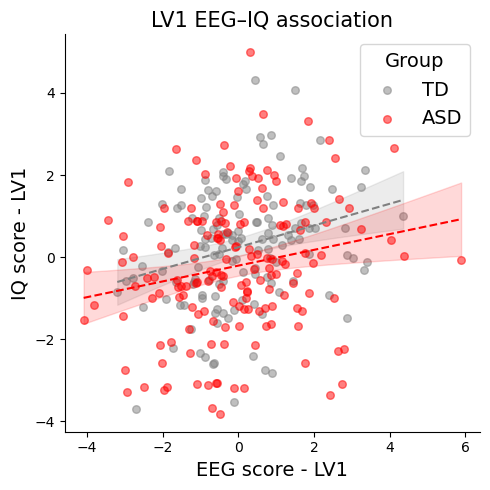

In [15]:
## Step 11 Part 1: Recreate LV1 score scatter plot with correct group colours  - Figure 5.1

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import t

analysis_name = "analysis_october"          # change this for each analysis

output_path = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_outputs\{analysis_name}'
scores = pd.read_csv(os.path.join(output_path, 'data', 'subject_scores.csv'), dtype={'UniqueID': str})
scores['UniqueID'] = scores['UniqueID'].astype(str)
scores_df = scores.merge(df_clean[['UniqueID', 'group_original']], on='UniqueID', how='left')

#print(scores_df.shape)
#print(scores_df['group_original'].value_counts())

def regression_ci(x, y, x_line, ci=0.95):
    n = len(x)
    m, b = np.polyfit(x, y, 1)
    y_hat = m * x + b
    residuals = y - y_hat
    se = np.sqrt(np.sum(residuals**2) / (n - 2))
    x_mean = np.mean(x)
    t_val = t.ppf((1 + ci) / 2, df=n - 2)
    se_line = se * np.sqrt(1/n + (x_line - x_mean)**2 / np.sum((x - x_mean)**2))
    y_line = m * x_line + b
    return y_line, se_line * t_val

group_colours = {'TD': 'grey', 'ASD': 'red'}

fig, ax = plt.subplots(figsize=(5, 5))

for group, colour in group_colours.items():
    subset = scores_df[scores_df['group_original'] == group]
    ax.scatter(subset['X_LV1'], subset['Y_LV1'],
               color=colour, alpha=0.5, s=30, label=group)
    x_arr = subset['X_LV1'].values
    y_arr = subset['Y_LV1'].values
    x_line = np.linspace(x_arr.min(), x_arr.max(), 200)
    y_line, ci_band = regression_ci(x_arr, y_arr, x_line)
    ax.plot(x_line, y_line, color=colour, linestyle='--', linewidth=1.5)
    ax.fill_between(x_line, y_line - ci_band, y_line + ci_band,
                    color=colour, alpha=0.15)

ax.set_xlabel('EEG score - LV1', fontsize=14)
ax.set_ylabel('IQ score - LV1', fontsize=14)
ax.set_title('LV1 EEG–IQ association', fontsize=15)
ax.legend(title='Group', fontsize=14, title_fontsize=14)

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\figure_5'
os.makedirs(fig_path, exist_ok=True)

plt.savefig(os.path.join(fig_path, 'figure5_1.png'), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure5_1.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure5_1.tif'),  dpi=300, bbox_inches='tight')

plt.show()

In [16]:
# Step 11 Part 2: Run three regression analyses for figure 5.1 (full sample + TD + ASD)

import pandas as pd
import numpy as np
from statsmodels.formula.api import ols

analysis_name = "analysis_october"

scores_path      =  rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_outputs\{analysis_name}'
participant_path = rf'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\pls_regression\plsdo_inputs\{analysis_name}'

scores       = pd.read_csv(os.path.join(scores_path, 'data', 'subject_scores.csv'), dtype={'UniqueID': str})
participants = pd.read_csv(os.path.join(participant_path, f'participants_{analysis_name}.csv'), dtype={'UniqueID': str})

df = scores.merge(participants[['UniqueID', 'group_original']], on='UniqueID', how='left')
print(f"Total N: {len(df)}")
print(df['group_original'].value_counts())

# Full sample
model_full = ols('Y_LV1 ~ X_LV1', data=df).fit()
r_full = df[['X_LV1', 'Y_LV1']].corr().iloc[0,1]

# TD only
df_td = df[df['group_original'] == 'TD']
model_td = ols('Y_LV1 ~ X_LV1', data=df_td).fit()
r_td = df_td[['X_LV1', 'Y_LV1']].corr().iloc[0,1]

# ASD only
df_asd = df[df['group_original'] == 'ASD']
model_asd = ols('Y_LV1 ~ X_LV1', data=df_asd).fit()
r_asd = df_asd[['X_LV1', 'Y_LV1']].corr().iloc[0,1]

for label, model, r, n in [('Full sample', model_full, r_full, len(df)),
                             ('TD',          model_td,   r_td,   len(df_td)),
                             ('ASD',         model_asd,  r_asd,  len(df_asd))]:
    print(f"{label} (N={n})")
    print(f"  β={model.params['X_LV1']:.4f}, p={model.pvalues['X_LV1']:.4f}, R²={model.rsquared:.4f}, r={r:.4f}")
    print()

results_5_1 = pd.DataFrame([
    {'group': label, 'N': n, 'beta': model.params['X_LV1'], 'p': model.pvalues['X_LV1'],
     'R2': model.rsquared, 'r': r}
    for label, model, r, n in [('Full sample', model_full, r_full, len(df)),
                               ('TD', model_td, r_td, len(df_td)),
                               ('ASD', model_asd, r_asd, len(df_asd))]
])
results_5_1.to_csv(os.path.join(fig_path, 'figure5_1_regression_results.csv'), index=False)

Total N: 307
group_original
ASD    166
TD     141
Name: count, dtype: int64
Full sample (N=307)
  β=0.2266, p=0.0000, R²=0.0548, r=0.2340

TD (N=141)
  β=0.2647, p=0.0009, R²=0.0762, r=0.2761

ASD (N=166)
  β=0.1923, p=0.0094, R²=0.0404, r=0.2009



In [ ]:
# Step 11: ANOVA — test whether the brain-IQ relationship differs between groups
# We merge the LV1 subject scores (from plsdo output) with demographic info
# then run the ANOVA model: Y_LV1 ~ X_LV1 + group + X_LV1:group

# Is the IQ composite score (Y_LV1) predicted by the EEG composite score (X_LV1), and does this relationship differ between ASD and TD?"
# The three parts are:
    # X_LV1 — main effect of EEG score on IQ score (is there a brain-IQ relationship overall?)
    # group — main effect of diagnosis (do ASD and TD differ in IQ score regardless of EEG?)
    # X_LV1:group — interaction (is the brain-IQ relationship stronger or weaker in one group compared to the other?)
# This tests whether the brain-IQ relationship (captured by LV1) differs between ASD and TD groups (as suggested by Eilidh)

In [17]:
# Step 11 Part 3: ANOVA + group comparisons (Mann whitney vs t-test)  on LV1 scores

import statsmodels.formula.api as smf
from scipy import stats

# 1. Normality check (Shapiro-Wilk) 

x_td  = df[df['group_original'] == 'TD']['X_LV1']
x_asd = df[df['group_original'] == 'ASD']['X_LV1']
y_td  = df[df['group_original'] == 'TD']['Y_LV1']
y_asd = df[df['group_original'] == 'ASD']['Y_LV1']

for label, arr in [('X_LV1 TD', x_td), ('X_LV1 ASD', x_asd),
                   ('Y_LV1 TD', y_td), ('Y_LV1 ASD', y_asd)]:
    stat, p = stats.shapiro(arr)
    print(f"Shapiro-Wilk {label}: W={stat:.3f}, p={p:.4f}")

# 2. ANOVA — does EEG-IQ relationship differ between groups? 
model = smf.ols('Y_LV1 ~ X_LV1 + group_original + X_LV1:group_original',
                data=df).fit()
print("\n", model.summary())

# 3. Group comparisons — auto-select test based on normality 

# if any distribution fails normality, we use the non-parametric test 
# for consistency across both comparisons.

alpha_shapiro = 0.05
all_normal = all([
    stats.shapiro(x_td)[1]  > alpha_shapiro,
    stats.shapiro(x_asd)[1] > alpha_shapiro,
    stats.shapiro(y_td)[1]  > alpha_shapiro,
    stats.shapiro(y_asd)[1] > alpha_shapiro
])

if all_normal:
    t_x, p_x = stats.ttest_ind(x_td, x_asd)
    t_y, p_y = stats.ttest_ind(y_td, y_asd)
    test_name = 't-test'
    stat_label = 't'
    s_x, s_y = t_x, t_y
else:
    s_x, p_x = stats.mannwhitneyu(x_td, x_asd, alternative='two-sided')
    s_y, p_y = stats.mannwhitneyu(y_td, y_asd, alternative='two-sided')
    test_name = 'Mann-Whitney'
    stat_label = 'U'

print(f"Normality satisfied: {all_normal} → using {test_name}")
print(f"X_LV1: {stat_label}={s_x:.3f}, p={p_x:.4f}")
print(f"Y_LV1: {stat_label}={s_y:.3f}, p={p_y:.4f}")

pd.DataFrame([{'variable': l, 'W': stats.shapiro(a)[0], 'p': stats.shapiro(a)[1]}
              for l, a in [('X_LV1 TD', x_td), ('X_LV1 ASD', x_asd), ('Y_LV1 TD', y_td), ('Y_LV1 ASD', y_asd)]]
             ).to_csv(os.path.join(fig_path, 'figure5_2_shapiro.csv'), index=False)

pd.DataFrame({'beta': model.params, 'SE': model.bse, 't': model.tvalues, 'p': model.pvalues}
             ).rename_axis('term').reset_index().to_csv(os.path.join(fig_path, 'figure5_2_interaction_model.csv'), index=False)

pd.DataFrame([{'variable': 'X_LV1', 'test': test_name, 'statistic': s_x, 'p': p_x},
              {'variable': 'Y_LV1', 'test': test_name, 'statistic': s_y, 'p': p_y}]
             ).to_csv(os.path.join(fig_path, 'figure5_2_group_tests.csv'), index=False)

Shapiro-Wilk X_LV1 TD: W=0.988, p=0.2755
Shapiro-Wilk X_LV1 ASD: W=0.991, p=0.4078
Shapiro-Wilk Y_LV1 TD: W=0.990, p=0.4345
Shapiro-Wilk Y_LV1 ASD: W=0.990, p=0.3035

                             OLS Regression Results                            
Dep. Variable:                  Y_LV1   R-squared:                       0.077
Model:                            OLS   Adj. R-squared:                  0.068
Method:                 Least Squares   F-statistic:                     8.430
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           2.13e-05
Time:                        16:14:34   Log-Likelihood:                -557.51
No. Observations:                 307   AIC:                             1123.
Df Residuals:                     303   BIC:                             1138.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    s

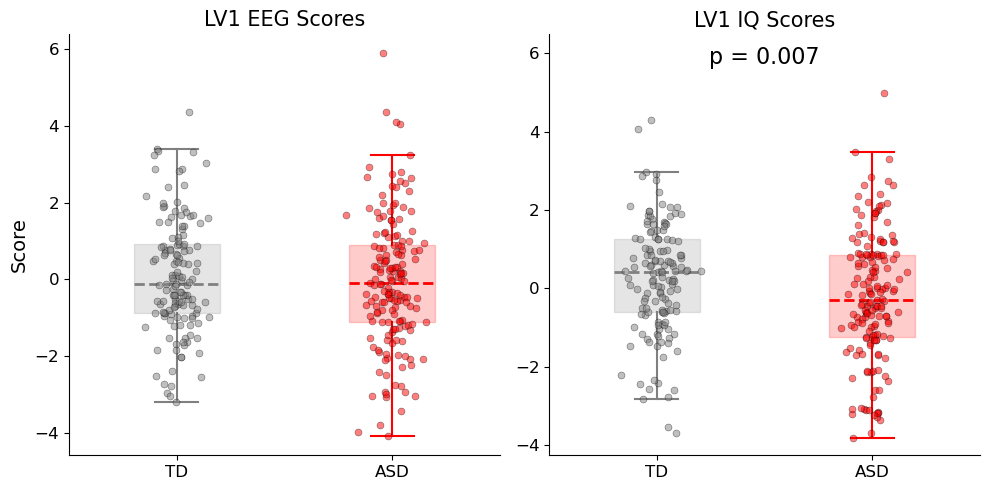

In [18]:
## Step 11 Part 4: Box plots of LV1 scores by group  Figure 5.2

group_colours = {'TD': 'grey', 'ASD': 'red'}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, col, title in zip(axes, ['X_LV1', 'Y_LV1'],
                           ['LV1 EEG Scores', 'LV1 IQ Scores']):
    for i, (group, colour) in enumerate(group_colours.items()):
        subset = df[df['group_original'] == group]
        bp = ax.boxplot(subset[col], positions=[i],
                   patch_artist=True,
                   widths=0.4,
                   boxprops=dict(facecolor=colour, alpha=0.2, edgecolor=colour),
                   medianprops=dict(color=colour, linewidth=2, linestyle='--'),
                   whiskerprops=dict(color=colour, linewidth=1.5),
                   capprops=dict(color=colour, linewidth=1.5),
                   flierprops=dict(marker='', markersize=0))
        x_jitter = np.random.normal(i, 0.06, size=len(subset))
        ax.scatter(x_jitter, subset[col],
                   color=colour, alpha=0.5, s=25,
                   edgecolors='black', linewidths=0.4, zorder=3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(list(group_colours.keys()), fontsize=12)
    ax.set_title(title, fontsize=15)
    if ax is axes[0]:
        ax.set_ylabel('Score', fontsize=14)  
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='y', labelsize=12)

# P-value annotation on Behaviour subplot (axes[1], Y_LV1) — uses p_y from Part 3
ax_b = axes[1]
vals_b = [df.loc[df['group_original'] == g, 'Y_LV1'].dropna() for g in group_colours.keys()]
y_top = max(v.max() for v in vals_b)
y_rng = y_top - min(v.min() for v in vals_b)
bar_h = y_top + 0.05 * y_rng
tick  = 0.02 * y_rng
p_txt = f'p = {p_y:.3f}' if p_y >= 0.001 else 'p < 0.001'
ax_b.text(0.5, bar_h+tick, p_txt, ha='center', va='bottom', fontsize=16)
ax_b.set_ylim(top=bar_h + 6*tick)

plt.tight_layout()

fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\figure_5'

plt.savefig(os.path.join(fig_path, 'figure5_2.png'), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure5_2.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure5_2.tif'), dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
## end 